# Informe

Clasificación de defectos superficiales PICADURA y RUSSET en palta Hass mediante ResNet50.

Se presentan el EDA, el Feature Engineering y la comparación de los experimentos. Los resultados se leen desde `7. resultados`. Los experimentos sin métricas guardadas aparecen como pendientes; no se calculan valores simulados.

## 1. Datos y unidad de análisis

El dataset original contiene 829 archivos: 710 PICADURA y 119 RUSSET. Cada archivo TIFF representa una palta con tres franjas, una por cámara; cada franja contiene distintas orientaciones del fruto.

Las 30 vistas de un mismo archivo no son 30 frutos independientes. Hasta contar con identificadores que relacionen archivos, la unidad experimental se mantiene como archivo completo.

El EDA encontro dos pares exactos entre particiones, incluido uno con etiquetas distintas. La auditoria local documentada excluyo cuatro archivos solo de las listas experimentales. Quedan 572 archivos train, 127 validation y 126 test reservado. Las exclusiones no alteraron los TIFF.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image

RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "README.md").exists() and (p / "7. resultados").exists()), None)
if RAIZ is None:
    raise FileNotFoundError("Abra el notebook desde la carpeta del proyecto.")
EDA = RAIZ / "7. resultados" / "eda"
FE = RAIZ / "7. resultados" / "feature_engineering"
SALIDA = RAIZ / "7. resultados" / "entrenamiento"
inventario = pd.read_csv(EDA / "eda_inventario.csv", encoding="utf-8-sig")
conteos = pd.crosstab(inventario["particion"], inventario["clase"])
conteos = conteos.reindex(["train", "validation", "test"])
conteos.loc["Total"] = conteos.sum()
display(conteos)

clase,PICADURA,RUSSET
particion,,
train,497,77
validation,107,21
test,106,21
Total,710,119


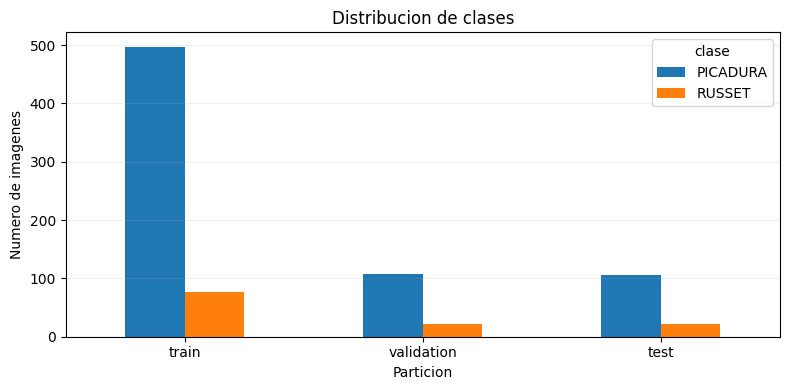

In [2]:
fig, ax = plt.subplots(figsize=(8,4))
conteos.drop(index="Total").plot.bar(ax=ax, rot=0)
ax.set(xlabel="Particion", ylabel="Numero de imagenes", title="Distribucion de clases")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

## 2. Feature Engineering

El análisis utilizo 24 imágenes originales de train, 12 por clase. Se revisaron dimensiones, brillo, contraste, histogramas de RGB, HSV y textura GLCM. Se compararon las entradas 224 x 224 y 256 x 512 mediante relleno proporcional.

El preprocesamiento de ResNet50 se verifico con un lote de forma `(4, 256, 512, 3)`. Esa comprobacion no es un entrenamiento ni una prediccion de clase.

Los descriptores manuales sirven para estudiar las imágenes; no se concatenaron a ResNet50.

In [3]:
tabla_fe = pd.read_csv(FE / "fe_caracteristicas_train.csv", encoding="utf-8-sig")
columnas = ["brillo_media", "contraste_rms", "glcm_contraste", "glcm_homogeneidad"]
display(tabla_fe.groupby("clase")[columnas].mean().round(4))
print("Imagenes analizadas en FE:", len(tabla_fe))

,brillo_media,contraste_rms,glcm_contraste,glcm_homogeneidad
clase,,,,
PICADURA,0.1168,0.1061,0.1814,0.9356
RUSSET,0.1287,0.1152,0.2203,0.9279


Imagenes analizadas en FE: 24


## 3. Experimentos de referencia

Se entrenaron las cabezas clasificadoras de ResNet50 con ImageNet congelada. B0 utilizo imágenes de 256 x 512 y V1 de 384 x 768. La comparación usa validation y no ajusta decisiones con test.

Macro-F1 es la métrica principal porque RUSSET es la clase minoritaria. Un valor de accuracy alto por si solo no demuestra buena identificacion de RUSSET.

In [4]:
def ultima_corrida_completa(condicion):
    carpetas = sorted(SALIDA.glob(f"{condicion}_s42_*"), key=lambda c: c.name, reverse=True)
    for carpeta in carpetas:
        ruta = carpeta / "metricas_validation.json"
        if ruta.is_file():
            met = json.loads(ruta.read_text(encoding="utf-8"))
            if met.get("estado") == "completo" and met.get("particion") == "validation":
                return carpeta, met
    return None, None


def tabla_metricas_guardadas():
    filas=[]
    for cond in ("B0", "V1", "D1", "D2", "FT_B0", "FT_D1", "FT_D2", "FT_V1"):
        carpeta, m = ultima_corrida_completa(cond)
        if m is not None:
            filas.append({"condicion": cond, "ejecucion": carpeta.name, "estado": "completo",
                         "accuracy": m.get("accuracy"), "macro_f1": m.get("macro_f1"),
                         "balanced_accuracy": m.get("balanced_accuracy"),
                         "recall_russet": m.get("recall_russet")})
        else:
            filas.append({"condicion": cond, "ejecucion": None, "estado": "pendiente",
                         "accuracy": np.nan, "macro_f1": np.nan,
                         "balanced_accuracy": np.nan, "recall_russet": np.nan})
    return pd.DataFrame(filas)

metricas = tabla_metricas_guardadas()
display(metricas.round(4))

,condicion,ejecucion,estado,accuracy,macro_f1,balanced_accuracy,recall_russet
0,B0,B0_s42_01,completo,0.8425,0.6604,0.6384,0.3333
1,V1,V1_s42_01,completo,0.8583,0.6598,0.6287,0.2857
2,D1,None,pendiente,NaN,NaN,NaN,NaN
3,D2,None,pendiente,NaN,NaN,NaN,NaN
4,FT_B0,None,pendiente,NaN,NaN,NaN,NaN
5,FT_D1,None,pendiente,NaN,NaN,NaN,NaN
6,FT_D2,None,pendiente,NaN,NaN,NaN,NaN
7,FT_V1,None,pendiente,NaN,NaN,NaN,NaN


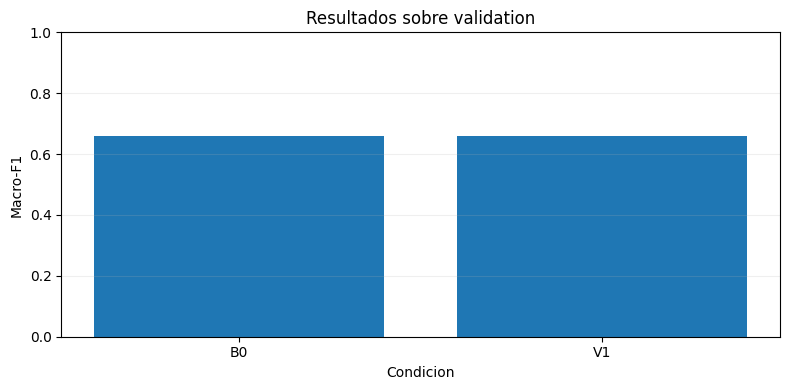

In [5]:
valores = metricas[metricas["estado"] == "completo"]
if len(valores):
    fig, ax = plt.subplots(figsize=(8,4))
    ax.bar(valores["condicion"], valores["macro_f1"])
    ax.set(xlabel="Condicion", ylabel="Macro-F1", ylim=(0,1), title="Resultados sobre validation")
    ax.grid(axis="y", alpha=0.2)
    fig.tight_layout()
    plt.show()
else:
    print("No hay metricas completas.")

## 4. Cambios de los datos en la siguiente comparación

D1 genera una copia fotométrica de cada RUSSET del conjunto train. D2 genera dos copias por RUSSET. El cambio consiste en aplicar brillo y contraste suaves a la imagen completa, sin cortar, voltear ni alterar la secuencia de capturas.

En el entrenamiento elegible hay 495 PICADURA y 77 RUSSET originales. D1 utiliza 77 copias adicionales; D2 utiliza 154. Estas copias no cuentan como frutos nuevos.

El generador solo prepara arrays RGB en memoria. Para cada copia queda registrado el archivo original, el número de copia y los factores utilizados. Las imágenes originales y los conjuntos validation/test permanecen intactos.

D1 y D2 no sustituyen las mediciones previas: son condiciones adicionales. Para evitar compensar dos veces el desbalance, los pesos por clase se recalculan con la distribución efectiva de cada condición.

,condicion,picadura,russet_original,copias_russet,russet_efectivo
0,B0,495,77,0,77
1,D1,495,77,77,154
2,D2,495,77,154,231


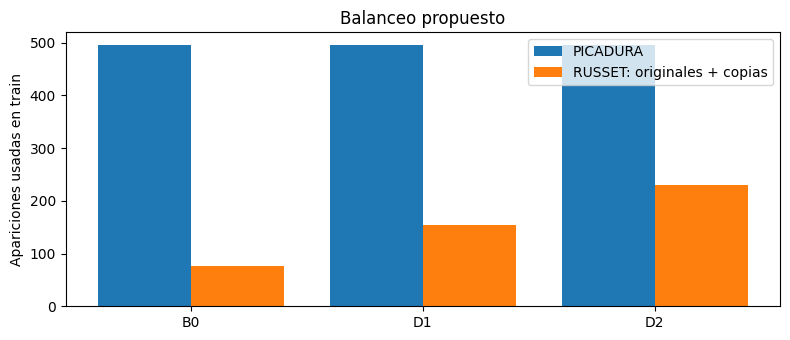

In [6]:
balance = pd.DataFrame([
    {"condicion": "B0", "picadura": 495, "russet_original": 77, "copias_russet": 0},
    {"condicion": "D1", "picadura": 495, "russet_original": 77, "copias_russet": 77},
    {"condicion": "D2", "picadura": 495, "russet_original": 77, "copias_russet": 154},
])
balance["russet_efectivo"] = balance["russet_original"] + balance["copias_russet"]
display(balance)
fig, ax = plt.subplots(figsize=(8,3.5))
x = np.arange(len(balance))
ax.bar(x-.2, balance["picadura"], width=.4, label="PICADURA")
ax.bar(x+.2, balance["russet_efectivo"], width=.4, label="RUSSET: originales + copias")
ax.set_xticks(x, balance["condicion"])
ax.set(ylabel="Apariciones usadas en train", title="Balanceo propuesto")
ax.legend()
fig.tight_layout()
plt.show()

## 5. Evidencia de entrenamiento

Se muestran los archivos de resultados existentes. Si D1, D2 o el fine-tuning aun no se ejecutaron, no aparecen graficos para esas condiciones.

Las curvas y matrices provienen de validation. Se mantiene la decision por fruto completo y el orden de clases PICADURA, RUSSET.

Condicion: B0 | Corrida: B0_s42_01


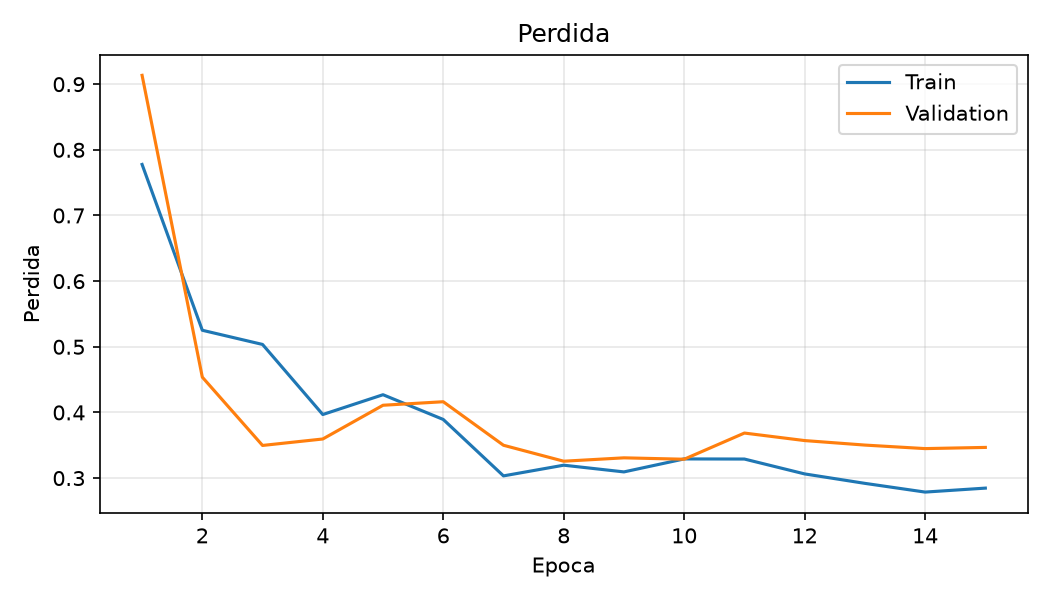

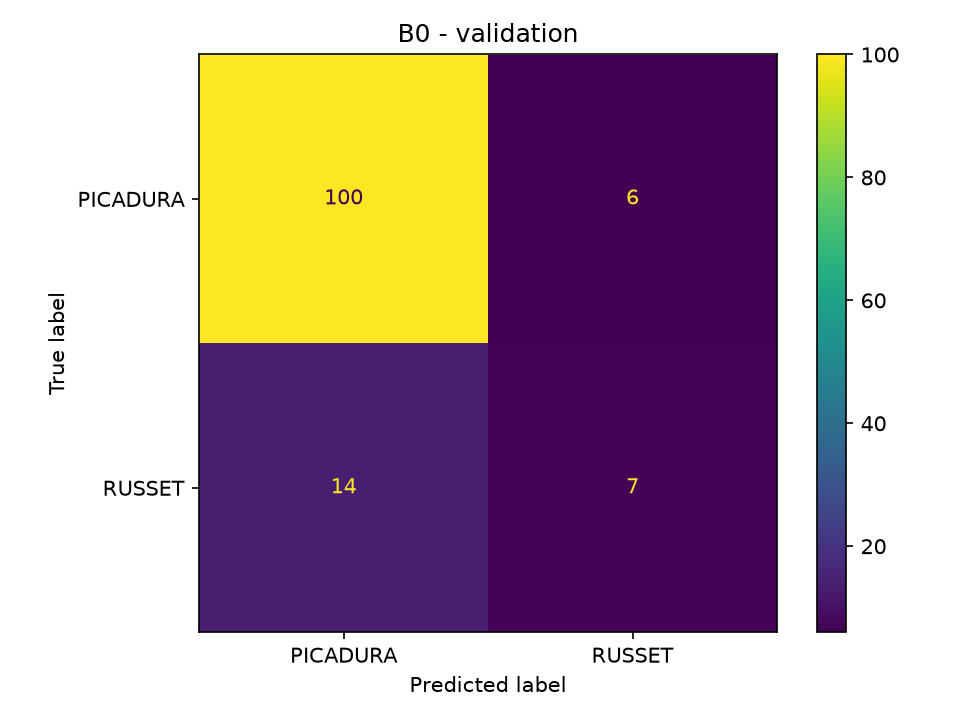

Condicion: V1 | Corrida: V1_s42_01


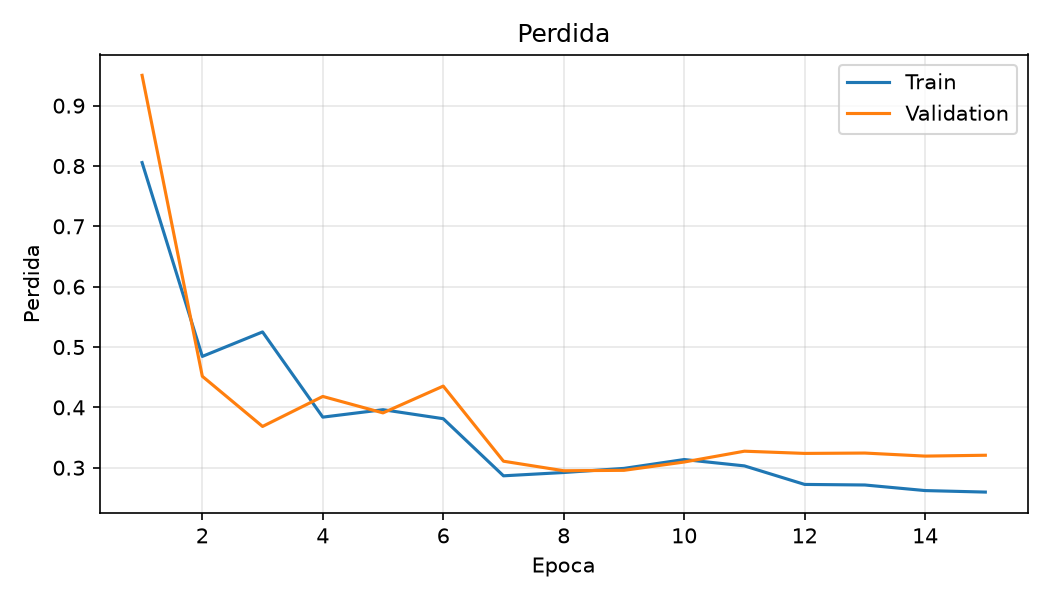

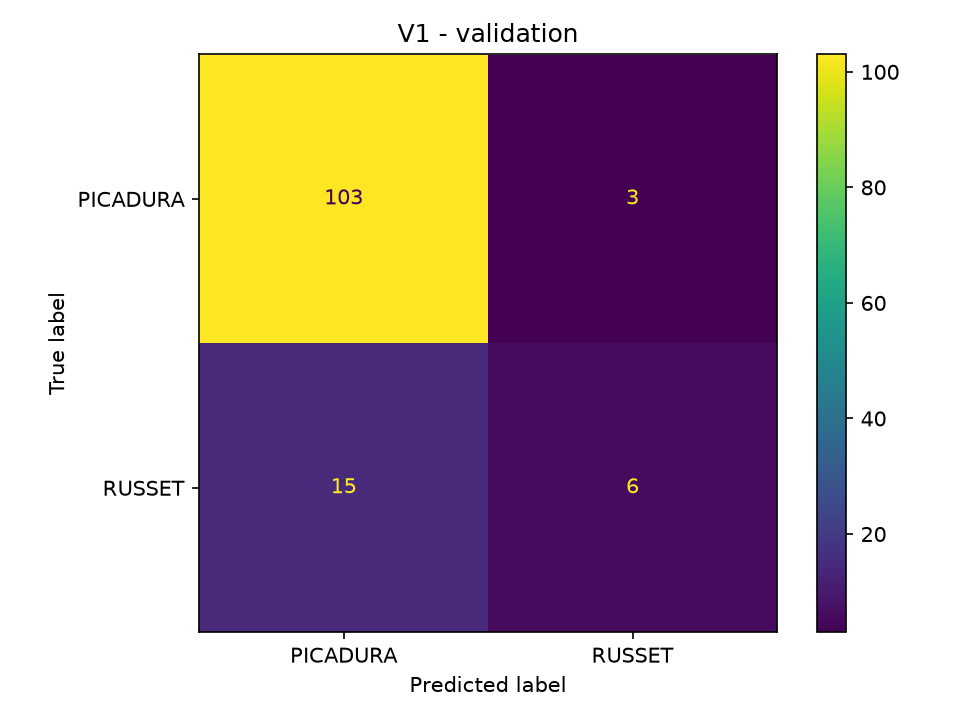

In [7]:
for condicion in ("B0", "V1", "D1", "D2", "FT_B0", "FT_D1"):
    carpeta, _ = ultima_corrida_completa(condicion)
    if carpeta is not None:
        rutas = [carpeta / "curva_loss.png", carpeta / "matriz_confusion_validation.png"]
        if all(r.is_file() for r in rutas):
            print("Condicion:", condicion, "| Corrida:", carpeta.name)
            for ruta in rutas:
                display(Image(filename=str(ruta), width=580))

## 6. Fine-tuning parcial

Despues de entrenar la cabeza congelada, se puede recuperar su checkpoint y ajustar las capas del bloque `conv5` de ResNet50, manteniendo BatchNormalization congelada. Se utiliza una tasa de aprendizaje baja (propuesta inicial: 1e-5).

Para comparar el efecto del balanceo bajo fine-tuning, ejecutar FT_B0 y FT_D1 con el mismo protocolo. No se debe comparar una version ajustada arbitrariamente frente a otra sin el mismo control.

El fine-tuning necesita leer imágenes en cada época. Puede ejecutarse con CPU, aunque la GPU resulta conveniente si hay memoria suficiente.

## 7. Consideraciones metodologicas

- Los 30 recortes de un mismo TIFF deben conservar la identidad del fruto si posteriormente se separan las vistas.
- Una etiqueta asignada al fruto no garantiza que el defecto se vea en cada recorte.
- Los duplicados exactos excluidos no descartan relaciones por lote o por varios archivos del mismo fruto.
- La augmentation fotométrica debe comprobarse visualmente para no ocultar lesiones.
- La seleccion de variantes se realiza solo con validation; test permanece reservado.
- Una sola semilla no permite demostrar superioridad estadistica. Conviene repetir los experimentos que resulten prometedores.

## 8. Ejecución y registro

1. Abrir `6. entrenamiento/resnet50.ipynb` con el kernel `palta`.
2. Ejecutar en modo seguro y revisar los duplicados.
3. Ejecutar D1. Comprobar `metricas_validation.json` y `copias_russet_train.csv`.
4. Ejecutar D2 si se desea medir el efecto de aumentar el número de copias.
5. Ejecutar FT_B0 y FT_D1 solo después de completar las corridas congeladas. La GPU es opcional.
6. Volver a este informe y pulsar Run All. Los cuadros y las figuras mostraran las nuevas métricas disponibles.

Las transformaciones no generan TIFF en el repositorio. Las imágenes y los pesos del modelo permanecen fuera de GitHub.